# Arbeitspaket (AP) 3: Machine Learning

**Prüfung – 40 Punkte**

### Persönliche Angaben (bitte ergänzen) und Prüfungsregeln

<table>
  <tr><td>Vorname:</td><td></td></tr>
  <tr><td>Nachname:</td><td></td></tr>
  <tr><td>Immatrikulationsnummer:</td><td></td></tr>
  <tr><td>Modul:</td><td>Data Science</td></tr>
  <tr><td>Datum / Zeit:</td><td>09.11.2026 / Prüfungsbeginn 08:00 Uhr</td></tr>
  <tr><td>Erlaubte Hilfsmittel:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Nicht erlaubt:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Technische Probleme:</td><td>Wenden Sie sich bei technischen Problemen umgehend an die Prüfungsaufsicht.</td></tr>
</table>

## Bewertungskriterien

| Teil | Aufgaben | Punkte |
|---|---|---:|
| A: Konzeptfragen mit Datenbezug | A1–A3 | 12 |
| B: Fehleranalyse und Korrektur | B1–B2 | 16 |
| C: Python-Code schreiben oder ergänzen | C1–C3 | 12 |
| **Total** | **8 Aufgaben** | **40** |

### Bewertungsschema

Jede Aufgabe wird für sich und **als Ganzes** bewertet. Ihre Punktzahl steht in der Überschrift.

<table>
  <thead>
    <tr><th>Kategorie</th><th>Beschreibung</th><th>Bewertung</th><th>4 Pkt</th><th>8 Pkt</th></tr>
  </thead>
  <tbody>
    <tr><td>Korrekt</td><td>Vollständig und fachlich einwandfrei: Antwort bzw. Begründung korrekt und nachvollziehbar; bei Code-Aufgaben liefert der Python-Code das richtige Ergebnis</td><td>100%</td><td>4</td><td>8</td></tr>
    <tr><td>Minimale Mängel</td><td>Kleine Fehler (z.B. fehlende Rundung, kleiner Rechenfehler bei richtigem Rechenweg) oder Begründung ungenau bzw. unvollständig</td><td>75%</td><td>3</td><td>6</td></tr>
    <tr><td>Mittlere Mängel</td><td>Ein wesentlicher Teil der Aufgabe ist korrekt gelöst. Eine weitere wesentliche Anforderung fehlt oder ist fachlich falsch.</td><td>50%</td><td>2</td><td>4</td></tr>
    <tr><td>Gravierende Mängel</td><td>Problem bzw. Ansatz erkennbar, aber Lösung oder Schlussfolgerung im Kern falsch (im Code z.B. ungeeigneter Lösungsweg wie Regressions- statt Classification Model)</td><td>25%</td><td>1</td><td>2</td></tr>
    <tr><td>Nicht lauffähig / nicht sinnvoll</td><td>Antwort fehlt, kein Bezug zur Aufgabe, oder Code nicht lauffähig (Syntax- oder Laufzeitfehler) und kein korrekter schriftlicher Teil.</td><td>0%</td><td>0</td><td>0</td></tr>
  </tbody>
</table>

Alternative, fachlich korrekte Lösungswege werden ebenfalls als korrekt gewertet.

## Hinweise zu den Daten

Der fiktive Baumarkt **«GartenWerk»** analysiert **1'200 unabhängig beobachtete Verkäufe neuer Werkzeuge unterschiedlicher Arten**. Er möchte den Preis anhand von Produkteigenschaften schätzen und vor dem Kauf abschätzen, ob ein Gerät innerhalb von 30 Tagen zurückgegeben wird.

Das Sortiment umfasst Rasenmäher, Motorhacken, Motorsägen, Heckenscheren, Rasentrimmer, Laubbläser, Hochdruckreiniger, Bohrmaschinen, Schleifmaschinen und Winkelschleifer (je 120 Verkäufe). Alle Geräte in diesem Datensatz sind elektrisch: Akku- oder Netzbetrieb. Die synthetischen Daten in `garden_tools.csv` sind bereits bereinigt und vollständig. Jede Zeile ist ein eigener Verkauf. Das Setup legt alle Features und die beiden Aufteilungen in 80 % Training / 20 % Test fest. Das Target `returned` ist erst nach dem Verkauf bekannt.

| Spalte | Bedeutung | Verwendung |
|---|---|---|
| `tool_id` | Eindeutige ID | kein Feature |
| `tool_type` | Werkzeugart (z.B. Motorhacke, Motorsäge, Bohrmaschine) | beschreibend, kein Model Feature |
| `motor_power_w` | Motorleistung, Watt | Feature für das Preismodell |
| `battery` | 1 = Akku, 0 = Netzbetrieb | beide Modelle |
| `weight_kg` | Gewicht, kg | beide Modelle |
| `noise_db` | Geräuschpegel gemäss Produktangabe, dB | Feature für die Rückgabevorhersage |
| `price_chf` | Verkaufspreis, CHF | Regression Target |
| `returned` | 1 = Rückgabe innert 30 Tagen, 0 = behalten | Classification Target |

Öffnen Sie das Notebook im Ordner AP03. Die Daten liegen in einer lokalen CSV-Datei; die Training Data und Test Data werden im vorgegebenen Setup erstellt. Weitere Spaltenbeschreibungen finden Sie in `garden_tool_data.xlsx`.

## Setup (vorgegeben, nicht bewertet)

Diese Zellen einmal von oben nach unten ausführen. Alle Daten liegen lokal vor.

In [ ]:
# Benötigte Bibliotheken importieren.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix

# Aktuelles Arbeitsverzeichnis anzeigen.
print('Working directory:', os.getcwd())

In [ ]:
# Werkzeugdaten aus der lokalen CSV-Datei laden.
df = pd.read_csv('garden_tools.csv')

# Umfang und erste Zeilen der Werkzeugdaten anzeigen.
print('Anzahl Zeilen und Spalten:', df.shape)
df.head()

In [ ]:
# Vorgegeben: 80 % Training Data und 20 % Test Data.
price_features = ['motor_power_w', 'weight_kg', 'battery']
return_features = ['weight_kg', 'noise_db', 'battery']

# Training Data und Test Data für die Preisvorhersage aufteilen.
X_train, X_test, y_train, y_test = train_test_split(
    df[price_features],
    df['price_chf'],
    test_size=0.20,
    random_state=42,
)

# Training Data und Test Data für die Rückgabevorhersage aufteilen.
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    df[return_features],
    df['returned'],
    test_size=0.20,
    random_state=42,
    stratify=df['returned'],
)

# Grösse der beiden Aufteilungen anzeigen.
print('Regression:', len(X_train), 'Train /', len(X_test), 'Test')
print('Classification:', len(X_train_class), 'Train /', len(X_test_class), 'Test')

---

<div style="background-color:#2E4057; color:white; padding:16px 24px; border-radius:6px; font-size:18px; margin-top:8px;">
&#9654;&nbsp; <strong>Ab hier beginnt die bewertete Prüfung — 40 Punkte</strong><br>
<span style="font-size:15px; font-weight:normal;">Tragen Sie Ihre Antworten direkt in die vorgesehenen Zellen ein und führen Sie alle Code-Zellen aus.</span>
</div>

Die Aufgaben sind unabhängig voneinander lösbar. Verändern Sie die im Setup geladenen Daten und Aufteilungen nicht; verwenden Sie eigene Variablen je Aufgabe. Teil B enthält bewusst fachlich fehlerhaften, aber lauffähigen Code.

**Schriftliche Antworten und Begründungen** tragen Sie jeweils in die Markdown-Zelle «Ihre Antwort / Begründung» unter der Aufgabe ein, Code in die zugehörige Codezelle.

---
## Teil A – Konzeptfragen (12 Punkte)

### A1 (4 Punkte)

«GartenWerk» möchte mit einem **Neural Network** die Probability vorhersagen, dass ein verkauftes Werkzeug zurückgegeben wird (`returned = 1`).

a) Welche Activation Function eignet sich für den Output Layer? Begründen Sie. (2 Punkte)

b) Das Modell sagt eine Rückgabe vorher, wenn die Probability über dem Decision Threshold (Standard: 0.5) liegt. GartenWerk möchte möglichst **wenige tatsächliche Rückgaben übersehen**. Wie sollte der Decision Threshold angepasst werden, und welchen Nachteil hat das? (2 Punkte)

**Ihre Antwort / Begründung:**

> [Hier eintragen]

### A2 (4 Punkte)

Ein **Logistic Regression Model** unterscheidet zurückgegebene (`returned = 1`) von behaltenen Werkzeugen (`returned = 0`). Auf den Test Data ergibt sich folgende ROC Curve:

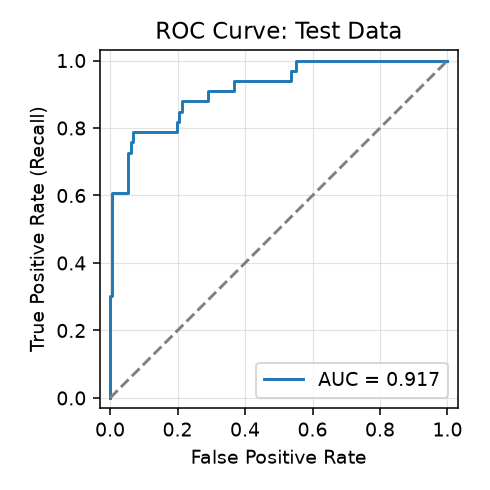

a) Ordnen Sie den gezeigten AUC-Wert ein: Wie gut unterscheidet das Modell die beiden Klassen im Vergleich zu zufälligem Raten und zu einer perfekten Trennung?

b) Ein Kollege sagt: *«Die AUC beträgt rund 0.9 – das Modell erkennt also rund 90 % der Rückgaben.»* Hat er recht? Begründen Sie.

**Ihre Antwort / Begründung:**

> [Hier eintragen]

### A3 (4 Punkte)

a) Beim Training eines Neural Network sinkt der **Training Loss** über alle Epochen, während der **Validation Loss** ab Epoche 15 wieder steigt. Was passiert hier, und wie kann **Early Stopping** helfen? (2 Punkte)

b) GartenWerk möchte Kundenkommentare automatisch als «positiv» oder «negativ» einordnen. 2'000 Kommentare wurden bereits von Hand entsprechend gekennzeichnet. Was dient beim Training als Features (`X`) und was als Target (`y`)? (2 Punkte)

**Hinweis zu b):** Denken Sie an das Vorlesungsthema **«From Words to Embeddings» (Week 8)** und die Verwendung von Textrepräsentationen für die Klassifikation.

**Ihre Antwort / Begründung:**

> [Hier eintragen]

---
## Teil B – Fehleranalyse (16 Punkte)

### B1 (8 Punkte)

**Ziel:** Mit dem vorgegebenen Linear Regression Model die Preise für drei neue Werkzeuge vorhersagen:

| Werkzeug | Motorleistung | Gewicht | Antrieb |
|---|---:|---:|---|
| Rasenmäher | 1'400 W | 18 kg | Akku |
| Bohrmaschine | 600 W | 2 kg | Akku |
| Hochdruckreiniger | 2'000 W | 14 kg | Netz |

Der DataFrame `output_B1` muss `tool` und `predicted_price_chf` (CHF, zwei Dezimalstellen) enthalten, eine Zeile je Werkzeug. Modell, Features und Aufteilung der Daten bleiben unverändert.

Geben Sie zusätzlich den **RMSE auf den Test Data** in CHF mit zwei Dezimalstellen aus.

Ein Verkäufer schaut sich die Ausgabe an: *«Ein Rasenmäher für über CHF 200'000 und ein RMSE von über CHF 1'300? Das kann nicht stimmen. Bitte überprüfen Sie die Berechnung.»*

**Aufgabe:** Schreiben Sie den korrigierten Code in die Codezelle (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben). Begründen Sie jede Änderung.

**Zu korrigierender Python-Code:**
```python
# Lineares Regressionsmodell mit den Training Data schätzen.
model_B1 = sm.OLS(y_train, sm.add_constant(X_train)).fit()

# Neue Werkzeuge erfassen: Rasenmäher (Akku), Bohrmaschine (Akku), Hochdruckreiniger (Netz).
new_tools = pd.DataFrame({
    'motor_power_w': [1.4, 0.6, 2.0],
    'weight_kg': [18000, 2000, 14000],
    'battery': [1, 1, 0],
})

# Preise für die neuen Werkzeuge vorhersagen und ausgeben.
pred_B1 = model_B1.predict(sm.add_constant(new_tools))
output_B1 = pd.DataFrame({
    'tool': ['Rasenmäher', 'Bohrmaschine', 'Hochdruckreiniger'],
    'predicted_price_chf': pred_B1.round(2),
})
print(output_B1.to_string(index=False))

# Vorhersagefehler auf den Test Data beurteilen.
pred_test_B1 = model_B1.predict(sm.add_constant(X_test))
rmse_B1 = mean_squared_error(y_test, pred_test_B1)
print('Test RMSE (CHF):', round(rmse_B1, 2))
```

**Ausgabe dieses Python-Codes vor der Korrektur:**

Diese Ausgabe zeigt den fehlerhaften Ausgangszustand, nicht das gesuchte korrekte Ergebnis.

```text
             tool  predicted_price_chf
       Rasenmäher            216040.66
     Bohrmaschine             24203.77
Hochdruckreiniger            167948.09
Test RMSE (CHF): 1346.33
```

**Ihre Antwort / Begründung:**

> [Hier eintragen]

In [ ]:
# Lineares Regressionsmodell mit den Training Data schätzen.

# Neue Werkzeuge erfassen: Rasenmäher (Akku), Bohrmaschine (Akku), Hochdruckreiniger (Netz).

# Preise für die neuen Werkzeuge vorhersagen und ausgeben.

# Vorhersagefehler auf den Test Data beurteilen.

### B2 (8 Punkte)

**Ziel:** Mit dem vorgegebenen Random Forest beurteilen, wie gut Rückgaben (`returned = 1`) bei **neuen, unbekannten** Werkzeugen erkannt werden. Trainiert wird mit den Training Data, beurteilt auf den Test Data.

Geben Sie Accuracy (drei Dezimalstellen) und Confusion Matrix aus. Die Matrix muss tatsächliche Klassen in den Zeilen und vorhergesagte Klassen in den Spalten zeigen, jeweils in der Reihenfolge `[0, 1]`. Features, Model Parameters und Datenaufteilung bleiben unverändert.

Der Analyst meldet: *«97 % Accuracy – das Modell erkennt fast jede Rückgabe.»*

**Aufgabe:** Schreiben Sie den korrigierten Code in die Codezelle (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben). Begründen Sie jede Änderung.

**Zu korrigierender Python-Code:**
```python
# Random Forest mit den vorgegebenen Parametern erstellen.
model_B2 = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42,
)

# Random Forest trainieren.
model_B2.fit(X_test_class, y_test_class)

# Klassen für die Test Data vorhersagen.
y_pred_B2 = model_B2.predict(X_test_class)

# Kennzahlen ausgeben.
print('Accuracy:', round(accuracy_score(y_test_class, y_pred_B2), 3))
print('Confusion Matrix:')
print(confusion_matrix(y_pred_B2, y_test_class, labels=[0, 1]))
```

**Ausgabe dieses Python-Codes vor der Korrektur:**

Diese Ausgabe zeigt den fehlerhaften Ausgangszustand, nicht das gesuchte korrekte Ergebnis.

```text
Accuracy: 0.971
Confusion Matrix:
[[206   6]
 [  1  27]]
```

**Ihre Antwort / Begründung:**

> [Hier eintragen]

In [ ]:
# Random Forest mit den vorgegebenen Parametern erstellen.

# Random Forest trainieren.

# Klassen für die Test Data vorhersagen.

# Kennzahlen ausgeben.

---
## Teil C – Python-Code schreiben oder ergänzen (12 Punkte)

### C1 (4 Punkte)

Erstellen Sie einen **Regression Tree** für `price_chf` **ohne Tiefenbegrenzung** (`random_state=42`) und trainieren Sie ihn mit `X_train` und `y_train`. Berechnen Sie den **RMSE** auf den Training Data und auf den Test Data (CHF, zwei Dezimalstellen). Vorhersagen und Grafik des Trees sind vorgegeben.

Beurteilen Sie anhand der beiden RMSE-Werte, wie gut der Tree auf neue Werkzeuge generalisiert. Nennen Sie eine Massnahme zur Verbesserung.

*Hinweis: Die Grafik zeigt nur die oberen Ebenen des Trees; `max_depth=2` in `plot_tree()` begrenzt nur die Darstellung.*

**Ihre Antwort / Begründung:**

> [Hier eintragen]

In [ ]:
# Regression Tree ohne Tiefenbegrenzung erstellen (random_state=42).
reg_tree = ...

# Regression Tree mit den Training Data trainieren.
...

# Vorgegeben: Vorhersagen für Training Data und Test Data erstellen.
pred_train_C1 = reg_tree.predict(X_train)
pred_C1 = reg_tree.predict(X_test)

# RMSE für Training Data und Test Data berechnen.
rmse_train_C1 = ...
rmse_test_C1 = ...

# Training RMSE und Test RMSE ausgeben.
print('Training RMSE (CHF):', round(rmse_train_C1, 2))
print('Test RMSE (CHF):', round(rmse_test_C1, 2))

# Vorgegeben: nur die oberen Ebenen des Trees darstellen.
plt.figure(figsize=(12, 5))
plot_tree(
    reg_tree,
    max_depth=2,
    feature_names=list(X_train.columns),
    filled=True,
    rounded=True,
    precision=1,
    fontsize=8,
)
plt.title('Regression Tree: obere Ebenen')
plt.tight_layout()
plt.show()

### C2 (4 Punkte)

Erstellen Sie ein **Random Forest Regression Model** für `price_chf` mit 100 Trees (`n_estimators=100`), `max_depth=5` und `random_state=42`. Trainieren Sie es mit `X_train` und `y_train`, sagen Sie die Preise für `X_test` vorher und berechnen Sie den **RMSE** auf den Test Data (CHF, zwei Dezimalstellen). Die Grafik der Feature Importance ist vorgegeben.

a) Ein Linear Regression Model mit denselben Features erreicht auf denselben Test Data einen RMSE von CHF 36.69. Lohnt sich das komplexere Modell? Begründen Sie.

b) Welches Feature ist für die Preisvorhersage am wichtigsten?

**Ihre Antwort / Begründung:**

> [Hier eintragen]

In [ ]:
# Random Forest Regressor mit n_estimators=100, max_depth=5 und random_state=42 erstellen.
reg_forest = ...

# Random Forest mit den Training Data trainieren.
...

# Preise für die Test Data vorhersagen.
pred_C2 = ...

# Test RMSE berechnen und ausgeben.
rmse_C2 = ...
print('RMSE (CHF):', round(rmse_C2, 2))

# Vorgegeben: Feature Importance als Bar Chart darstellen.
importance = pd.Series(reg_forest.feature_importances_, index=X_train.columns)
importance.sort_values().plot(kind='barh', color='darkred', figsize=(6, 3))
plt.xlabel('Feature Importance')
plt.title('Random Forest: Preis')
plt.tight_layout()
plt.show()

### C3 (4 Punkte)

Erstellen Sie einen **Gradient Boosting Classifier** für `returned` mit 100 Trees (`n_estimators=100`), `max_depth=2`, `learning_rate=0.1` und `random_state=42` und trainieren Sie ihn mit `X_train_class` und `y_train_class`. Vorhersage, Accuracy und Confusion Matrix sind vorgegeben (Zeilen: tatsächliche, Spalten: vorhergesagte Klassen, jeweils `[0, 1]`).

**Frage:** GartenWerk möchte möglichst wenige tatsächliche Rückgaben übersehen. Die Accuracy liegt über 90 %. Ist das Modell beim Decision Threshold von 0.5 (den `predict()` verwendet) für dieses Ziel geeignet? Begründen Sie mit der Confusion Matrix.

**Ihre Antwort / Begründung:**

> [Hier eintragen]

In [ ]:
# Gradient Boosting Classifier mit n_estimators=100, max_depth=2, learning_rate=0.1 und random_state=42 erstellen.
clf_boosting = ...

# Gradient Boosting Classifier mit den Training Data trainieren.
...

# Vorgegeben: Klassen für die Test Data vorhersagen.
pred_C3 = clf_boosting.predict(X_test_class)

# Vorgegeben: Kennzahlen berechnen; Zeilen tatsächlich, Spalten vorhergesagt (jeweils 0, 1).
cm_C3 = confusion_matrix(y_test_class, pred_C3, labels=[0, 1])
print('Accuracy:', round(accuracy_score(y_test_class, pred_C3), 3))
print('Confusion Matrix:')
print(cm_C3)

---
### Notebook-Footer (vorgegeben)

In [ ]:
# Bibliotheken für die technischen Angaben laden.
import platform
from datetime import datetime

# Python-Version, Betriebssystem und Zeitpunkt ausgeben.
print('Python:', platform.python_version())
print('System:', platform.system())
print('Zeitpunkt:', datetime.now().isoformat(timespec='seconds'))